# Modeling: خوشه‌بندی، قوانین انجمنی، ناهنجاری و پیش‌بینی ریزش مشتری (Online Retail)

**ترتیب این نوت‌بوک:**

1. بازسازی داده‌ی آماده‌شده (cutoff، label و RFM)
2. خوشه‌بندی مشتریان با KMeans و سنجش نرخ ریزش هر خوشه
3. قوانین انجمنی (Apriori) و تبدیل آن‌ها به ویژگی برای هر مشتری
4. ناهنجاری سطح مشتری و سطح روز
5. classification ریزش (Logistic، Random Forest) و رتبه‌بندی ۵۰۰ مشتری پرخطر
6. جمع‌بندی و محدودیت‌ها

In [5]:
for name in ["df", "df_clean", "sales", "before", "label_table", "n_invoices", "recency", "monetary", "features", "features_log", "X"]:
    print(name, name in globals())

df True
df_clean True
sales True
before True
label_table True
n_invoices True
recency False
monetary False
features False
features_log False
X False


### بازسازی داده: خواندن و پاک‌سازی (مراحل ۱ و ۲ آماده‌سازی)

**چرا؟** این سلول فایل اصلی را می‌خواند و ردیف‌هایی را که «خرید واقعی مشتری» نیستند با ثبت دلیل کنار می‌گذارد: فاکتورهای حسابداری (شروع با A)، کدهای غیرکالا (POST، Bank Charges و ...)، قیمت صفر و ردیف‌های تکراری. هیچ مقدار خالی (null) پر نشد.

**تحلیل:** از ۵۴۱٬۹۰۹ ردیف، ۵۳۱٬۲۰۵ ردیف ماند، ۲٬۹۴۷ ردیف به جدول غیرکالا رفت و ۷٬۷۵۷ ردیف حذف شد. جمع این سه برابر کل است (`True`)، پس هیچ ردیفی گم نشده.

In [6]:
import pandas as pd
import numpy as np


df = pd.read_excel("/home/helia/Documents/BaseDir/online+retail/Online Retail.xlsx")
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
df["is_cancel"] = df["InvoiceNo"].str.startswith("C")

df_clean = df.copy()
removed = []


mask = df_clean["InvoiceNo"].str.startswith("A")
removed.append(df_clean[mask].assign(reason="bad_debt"))
df_clean = df_clean[~mask]


non_product = ["POST", "DOT", "M", "m", "C2", "D", "S","BANK CHARGES", "AMAZONFEE", "CRUK", "B", "PADS"]
mask = df_clean["StockCode"].isin(non_product) | df_clean["StockCode"].str.startswith("gift_")
service_lines = df_clean[mask].copy()
df_clean = df_clean[~mask]


mask = df_clean["UnitPrice"] <= 0
removed.append(df_clean[mask].assign(reason="zero_price"))
df_clean = df_clean[~mask]


mask = df_clean.duplicated()
removed.append(df_clean[mask].assign(reason="duplicate"))
df_clean = df_clean[~mask]


excluded = pd.concat(removed)
print(len(df), len(df_clean), len(service_lines), len(excluded))
print(len(df) == len(df_clean) + len(service_lines) + len(excluded))

541909 531205 2947 7757
True


### بازسازی داده: cutoff و ساخت label (مرحله ۳ آماده‌سازی)

**چرا؟** تاریخ ۲۰۱۱-۰۹-۱۱ را برش می‌گذاریم: رفتار از قبل آن و برچسب از ۹۰ روز بعدش می‌آید. مشتری‌ای که قبل از cutoff خرید داشته و بعد از آن هیچ خریدی ندارد «ریزشی» است. این یک **تعریف ماست**، نه چیزی که در داده ثبت شده باشد. مشتریان حداقل دو فاکتور برای classification علامت خورده‌اند.

**تحلیل:** ۴٬۳۳۴ مشتری شناخته‌شده؛ ۳٬۳۶۸ نفرشان قبل از cutoff خرید داشتند و ۱٬۴۴۹ نفر (حدود ۴۳٪) ریزشی‌اند. ۱٬۹۹۸ مشتری حداقل دو فاکتور دارند.

In [7]:
sales = df_clean[(df_clean["is_cancel"] == False) & (df_clean["CustomerID"].notna())].copy()
sales["CustomerID"] = sales["CustomerID"].astype(int)
print(sales.shape, sales["CustomerID"].nunique())


cutoff = pd.Timestamp("2011-09-11")
before = sales[sales["InvoiceDate"] < cutoff]
after = sales[sales["InvoiceDate"] >= cutoff]
customers_before = before["CustomerID"].unique()
customers_after = after["CustomerID"].unique()


returned = set(customers_after)
churn_ids = [c for c in customers_before if c not in returned]
print(len(customers_before), len(churn_ids))

# جدول label
label_table = pd.DataFrame({"CustomerID": customers_before})
label_table["churn"] = label_table["CustomerID"].isin(churn_ids).astype(int)
n_invoices = before.groupby("CustomerID")["InvoiceNo"].nunique()
label_table["n_invoices"] = label_table["CustomerID"].map(n_invoices)
label_table["for_classification"] = (label_table["n_invoices"] >= 2).astype(int)
print(label_table.shape, label_table["churn"].sum(), label_table["for_classification"].sum())

(391150, 9) 4334
3368 1449
(3368, 4) 1449 1998


### بازسازی داده: ساخت RFM و ذخیره‌ی فایل‌ها (مرحله ۴ آماده‌سازی)

**چرا؟** سه شاخص کلاسیک را فقط از داده‌ی قبل از cutoff می‌سازیم: **Recency** (روز از آخرین خرید تا cutoff)، **Frequency** (تعداد فاکتور) و **Monetary** (مجموع خرج). بعد جدول‌ها را ذخیره می‌کنیم تا بخش Modeling از همین‌جا شروع کند.

**تحلیل:** جدول `(3368, 4)` و بدون مقدار خالی است. recency از ۱ تا ۲۸۳ روز با میانه‌ی ۷۴، frequency از ۱ تا ۱۳۱ با میانه‌ی ۲، و monetary بسیار کج است (میانه ۵۵۵ ولی بیشینه حدود ۱۷۷٬۰۰۰).

In [8]:
before = before.copy()
before["TotalPrice"] = before["Quantity"] * before["UnitPrice"]

last_purchase = before.groupby("CustomerID")["InvoiceDate"].max()
recency = (cutoff - last_purchase).dt.days
monetary = before.groupby("CustomerID")["TotalPrice"].sum()

features = label_table[["CustomerID"]].copy()
features["recency"] = features["CustomerID"].map(recency)
features["frequency"] = features["CustomerID"].map(n_invoices)
features["monetary"] = features["CustomerID"].map(monetary)
print(features.shape, features.isna().sum().sum())


features[["CustomerID", "recency", "frequency", "monetary"]].to_csv("features_rfm.csv", index=False)
label_table.to_csv("label_table.csv", index=False)
df_clean.to_csv("df_clean.csv", index=False)
print("done")

(3368, 4) 0
done


### خواندن فایل‌های آماده‌شده

**چرا؟** این نوت‌بوک تازه است و هیچ متغیری ندارد. سه فایلی را که در نوت‌بوک Data Preparation ذخیره کردیم می‌خوانیم: ویژگی‌های RFM، جدول label و تراکنش‌های تمیز. `parse_dates` لازم است چون CSV تاریخ را متن می‌خواند. تاریخ cutoff را هم دوباره تعریف می‌کنیم چون مقدار متغیرها در فایل ذخیره نمی‌شود.

**تحلیل:** شکل‌ها باید `(3368, 4)`، `(3368, 4)` و `(531205, 9)` باشند. یعنی ۳٬۳۶۸ مشتری با سابقه‌ی خرید قبل از cutoff و ۵۳۱٬۲۰۵ ردیف تراکنش تمیز داریم.

In [9]:
import pandas as pd

features = pd.read_csv("features_rfm.csv")
label_table = pd.read_csv("label_table.csv")
df_clean = pd.read_csv("df_clean.csv", parse_dates=["InvoiceDate"])
cutoff = pd.Timestamp("2011-09-11")

print(features.shape, label_table.shape, df_clean.shape)

(3368, 4) (3368, 4) (531205, 9)


### لگاریتم روی ویژگی‌های کج

**چرا؟** KMeans با فاصله کار می‌کند. `monetary` خیلی کج است (میانه ۵۵۵ ولی بیشینه حدود ۱۷۷٬۰۰۰) و چند مشتری خیلی بزرگ خوشه‌بندی را به خود می‌کشند. لگاریتم اعداد بزرگ را فشرده می‌کند. از `log1p` استفاده شد تا مقدار صفر مشکل نسازد. روی `recency` لازم نبود چون کجی‌اش کم است.

**تحلیل:** کجی (skew) بعد از لگاریتم کاهش یافت:

| ویژگی | قبل | بعد |
|---|---|---|
| recency | ۰٫۷۶ | ۰٫۷۶ (بدون تغییر) |
| frequency | ۹٫۱۷ | ۱٫۳۸ |
| monetary | ۱۶٫۲۸ | ۰٫۴۱ |

In [10]:
import numpy as np

features_log = features[["recency", "frequency", "monetary"]].copy()
features_log["frequency"] = np.log1p(features_log["frequency"])
features_log["monetary"] = np.log1p(features_log["monetary"])

print(features[["recency", "frequency", "monetary"]].skew().round(2))
print(features_log.skew().round(2))

recency       0.76
frequency     9.17
monetary     16.28
dtype: float64
recency      0.76
frequency    1.38
monetary     0.41
dtype: float64


### هم‌مقیاس کردن (StandardScaler)

**چرا؟** `recency` بین ۱ تا ۲۸۳ است ولی `frequency` و `monetary` بعد از لگاریتم حدود ۱ تا ۱۲. بدون scaling، KMeans تقریباً فقط به `recency` نگاه می‌کند. `StandardScaler` هر ستون را به میانگین ۰ و انحراف معیار ۱ می‌رساند تا هر سه شاخص هم‌وزن شوند.

**تحلیل:** در خروجی `mean` همه ۰ و `std` همه ۱ است. مقدارهای `X` دیگر روز یا پول نیستند و «تعداد انحراف معیار از میانگین» هستند. برای توصیف خوشه‌ها به جدول اصلی برمی‌گردیم. چون clustering بدون label و فقط با داده‌ی قبل از cutoff انجام می‌شود، scaling روی همه‌ی مشتری‌ها نشت اطلاعات ایجاد نمی‌کند.

In [11]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X = scaler.fit_transform(features_log)

X_df = pd.DataFrame(X, columns=["recency", "frequency", "monetary"])
print(X_df.describe().round(2))

       recency  frequency  monetary
count  3368.00    3368.00   3368.00
mean     -0.00       0.00      0.00
std       1.00       1.00      1.00
min      -1.18      -0.87     -4.14
25%      -0.86      -0.87     -0.69
50%      -0.27      -0.22     -0.07
75%       0.71       0.59      0.67
max       2.35       5.82      4.66


### انتخاب تعداد خوشه (k)

**چرا؟** KMeans باید از قبل بداند چند خوشه بسازد. دو معیار را برای k از ۲ تا ۸ حساب کردیم: **Inertia** (مجموع فاصله‌ی مشتری‌ها تا مرکز خوشه‌شان که با زیاد شدن k همیشه کم می‌شود و دنبال «آرنج» می‌گردیم) و **Silhouette** (میزان جدا بودن خوشه‌ها، بین ۱- و ۱).

**تحلیل:**

| k | Inertia | Silhouette |
|---|---|---|
| 2 | 5228.0 | 0.411 |
| 3 | 3520.5 | 0.373 |
| 4 | 2724.5 | 0.345 |
| 5 | 2346.9 | 0.325 |
| 6 | 2029.0 | 0.317 |
| 7 | 1824.5 | 0.302 |
| 8 | 1672.8 | 0.280 |

تا k=4 کاهش inertia بزرگ است (۱۷۰۷ و بعد ۷۹۶) و بعد از آن کوچک و تقریباً ثابت. آرنج حدود ۴ است. Silhouette برای k=2 بالاترین است ولی k=2 فقط مشتری‌ها را به دو گروه کلی تقسیم می‌کند و برای تحلیل رفتار کم‌فایده است. مقدار حدود ۰٫۳۵ یعنی ساختار خوشه‌ای متوسط است، که برای رفتار مشتری که پیوستار است طبیعی است. **k=4** را انتخاب کردیم. این یک قضاوت تحلیلی است، نه نتیجه‌ی قطعی ریاضی.

In [12]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    print(k, round(km.inertia_, 1), round(silhouette_score(X, labels), 3))

2 5228.0 0.411
3 3520.5 0.373
4 2724.5 0.345
5 2346.9 0.325
6 2029.0 0.317
7 1824.5 0.302
8 1672.8 0.28


### اجرای KMeans با k=4

**چرا؟** طبق تصمیم سلول قبل، مشتری‌ها را به چهار گروه رفتاری تقسیم می‌کنیم. `random_state=42` نتیجه را تکرارپذیر می‌کند و `n_init=10` یعنی ده شروع تصادفی مختلف و نگه داشتن بهترین.

**تحلیل:** اندازه‌ی خوشه‌ها: ۱۱۱۸، ۸۸۶، ۴۷۹ و ۸۸۵ مشتری. شماره‌ی خوشه فقط اسم است، نه رتبه.

In [13]:
km = KMeans(n_clusters=4, random_state=42, n_init=10)
features["cluster"] = km.fit_predict(X)

print(features["cluster"].value_counts().sort_index())

cluster
0    1118
1     886
2     479
3     885
Name: count, dtype: int64


### توصیف خوشه‌ها

**چرا؟** باید بفهمیم هر خوشه چه نوع مشتری است. میانگین ویژگی‌ها را به واحد اصلی (روز، تعداد، مبلغ) حساب می‌کنیم، چون اعداد scaled معنای روز و پول ندارند.

**تحلیل:**

| خوشه | recency | frequency | monetary | تعداد | تفسیر |
|---|---|---|---|---|---|
| ۰ | ۵۶٫۷ | ۳٫۳ | ۱۳۰۳٫۸ | ۱۱۱۸ | مشتری منظم متوسط |
| ۱ | ۲۰۸٫۳ | ۱٫۲ | ۳۵۱٫۴ | ۸۸۶ | دورشده (مدت‌هاست نیامده) |
| ۲ | ۲۴٫۴ | ۱۲٫۲ | ۶۹۳۹٫۵ | ۴۷۹ | مشتری برتر |
| ۳ | ۶۹٫۰ | ۱٫۴ | ۳۰۱٫۱ | ۸۸۵ | جدید یا کم‌خرید |

نام‌ها برچسب تفسیری ما از روی اعداد هستند، نه خروجی الگوریتم. خوشه‌های ۱ و ۳ هر دو تقریباً تک‌فاکتوره‌اند و تفاوتشان در recency است: تازه‌وارد در برابر رهاشده.

In [14]:
profile = features.groupby("cluster")[["recency", "frequency", "monetary"]].mean().round(1)
profile["size"] = features["cluster"].value_counts().sort_index()
print(profile)

         recency  frequency  monetary  size
cluster                                    
0           56.7        3.3    1303.8  1118
1          208.3        1.2     351.4   886
2           24.4       12.2    6939.5   479
3           69.0        1.4     301.1   885


### اضافه کردن label به جدول ویژگی‌ها

**چرا؟** تا اینجا clustering بدون label انجام شد و باید هم همین‌طور باشد. حالا برای **ارزیابی** از label استفاده می‌کنیم تا ببینیم خوشه‌ها به ریزش ربط دارند. از `merge` روی `CustomerID` استفاده شد تا ترتیب ردیف‌ها مهم نباشد.

**تحلیل:** شکل جدول `(3368, 6)` شد: شناسه، سه شاخص RFM، خوشه و churn.

In [15]:
features = features.merge(label_table[["CustomerID", "churn"]], on="CustomerID")

print(features.shape)
print(features.head())

(3368, 6)
   CustomerID  recency  frequency  monetary  cluster  churn
0       17850      282         34   5391.21        2      1
1       13047       37          8   2682.01        2      0
2       12583       16          9   3908.21        2      0
3       13748        5          5    948.25        0      1
4       15100      243          3    876.00        1      1


### نرخ ریزش هر خوشه

**چرا؟** میانگین ستون `churn` همان نرخ ریزش است. اگر خوشه‌ها معنادار باشند، نرخ ریزش‌شان باید فرق کند.

**تحلیل:**

| خوشه | نرخ ریزش | ریزشی | کل |
|---|---|---|---|
| ۰ | ۳۱٫۸٪ | ۳۵۵ | ۱۱۱۸ |
| ۱ | ۶۶٫۱٪ | ۵۸۶ | ۸۸۶ |
| ۲ | ۶٫۷٪ | ۳۲ | ۴۷۹ |
| ۳ | ۵۳٫۸٪ | ۴۷۶ | ۸۸۵ |

نرخ کل ۴۳٪ است. خوشه‌ها ریزش را خوب تفکیک می‌کنند (۶٫۷٪ تا ۶۶٪). دو احتیاط: خوشه‌ها بر اساس recency هم ساخته شده‌اند و رابطه‌ی قوی با ریزش (که نبود خرید است) انتظار می‌رفت، و خوشه‌ی ۳ مبهم است چون شامل مشتریان تازه‌ای است که شاید فرصت نکرده‌اند دوباره بخرند.

In [16]:
churn_by_cluster = features.groupby("cluster")["churn"].agg(["mean", "sum", "count"])
print(churn_by_cluster.round(3))
print(features["churn"].mean().round(3))

          mean  sum  count
cluster                   
0        0.318  355   1118
1        0.661  586    886
2        0.067   32    479
3        0.538  476    885
0.43


### نمودار نرخ ریزش هر خوشه

**چرا؟** تفاوت خوشه‌ها در نمودار یک‌نگاه دیده می‌شود. خط قرمز نقطه‌چین نرخ کل (۴۳٪) است.

**تحلیل:** خوشه‌ی ۲ بسیار پایین‌تر از خط است (حدود ۷٪) و خوشه‌ی ۰ کمی پایین‌تر. خوشه‌های ۳ و ۱ بالای خط‌اند (حدود ۵۴٪ و ۶۶٪).

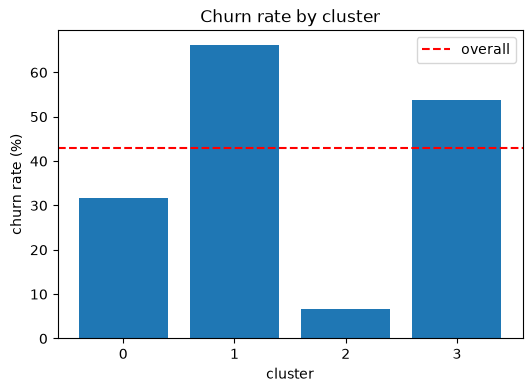

In [17]:
import matplotlib.pyplot as plt

rate = features.groupby("cluster")["churn"].mean()

plt.figure(figsize=(6, 4))
plt.bar(rate.index.astype(str), rate.values * 100)
plt.axhline(features["churn"].mean() * 100, color="red", linestyle="--", label="overall")
plt.xlabel("cluster")
plt.ylabel("churn rate (%)")
plt.title("Churn rate by cluster")
plt.legend()
plt.show()

### ساخت جدول کالا–فاکتور (قوانین انجمنی)

**چرا؟** برای قوانین انجمنی هر فاکتور یک «سبد» است و فقط حضور هر کالا مهم است. تصمیم‌ها: فقط داده‌ی قبل از cutoff (برای جلوگیری از نشت)، همه‌ی فاکتورها حتی بدون CustomerID (چون الگوی سبد به هویت مشتری نیاز ندارد)، فاکتورهای لغوشده حذف شدند، و هر کالا در هر فاکتور یک بار (`drop_duplicates`). `astype(str)` لازم است چون کدهای عددی و متنی در CSV ترکیب می‌شوند.

**تحلیل:** ۳۱۹٬۶۴۴ ردیف (فاکتور، کالا)، ۱۲٬۸۹۷ فاکتور و ۳٬۶۶۲ کالای متفاوت.

In [18]:
basket_lines = df_clean[(df_clean["is_cancel"] == False) & (df_clean["InvoiceDate"] < cutoff)].copy()

basket_lines["InvoiceNo"] = basket_lines["InvoiceNo"].astype(str)
basket_lines["StockCode"] = basket_lines["StockCode"].astype(str)

basket_lines = basket_lines[["InvoiceNo", "StockCode"]].drop_duplicates()

print(basket_lines.shape)
print(basket_lines["InvoiceNo"].nunique(), basket_lines["StockCode"].nunique())

(319644, 2)
12897 3662


### نگه داشتن کالاهای پرتکرار

**چرا؟** قانون روی کالای کم‌فروش شانسی و غیرقابل‌اعتماد است و تعداد زیاد کالا الگوریتم را کند می‌کند. فقط کالاهایی را نگه داشتیم که در حداقل ۱۰۰ فاکتور آمده‌اند. عدد ۱۰۰ انتخاب ماست و قابل تغییر است.

**تحلیل:** از ۳٬۶۶۲ کالا، ۱٬۰۰۰ کالا ماند و ۲۳۸٬۹۶۲ ردیف باقی ماند.

In [19]:
item_counts = basket_lines["StockCode"].value_counts()
frequent_items = item_counts[item_counts >= 100].index

basket_lines = basket_lines[basket_lines["StockCode"].isin(frequent_items)]

print(len(frequent_items))
print(basket_lines.shape)

1000
(238962, 2)


### حذف سبدهای کوچک

**چرا؟** قانون یعنی «کالای A همراه با کالای B»، پس سبد تک‌کالایی نمی‌تواند قانون بسازد.

**تحلیل:** ۱۱٬۴۸۵ فاکتور با ۱٬۰۰۰ کالا و ۲۳۷٬۹۶۶ ردیف ماند. بیش از ۹۹٪ داده‌ی سبد حفظ شد.

In [20]:
basket_size = basket_lines.groupby("InvoiceNo").size()
good_invoices = basket_size[basket_size >= 2].index

basket_lines = basket_lines[basket_lines["InvoiceNo"].isin(good_invoices)]

print(basket_lines.shape)
print(basket_lines["InvoiceNo"].nunique(), basket_lines["StockCode"].nunique())

(237966, 2)
11485 1000


### ساخت ماتریس سبد (فاکتور × کالا)

**چرا؟** الگوریتم Apriori جدولی می‌خواهد که هر ردیف یک فاکتور، هر ستون یک کالا و هر خانه `True/False` باشد. `pd.crosstab` شمارش می‌سازد و `astype(bool)` آن را به True/False تبدیل می‌کند.

**تحلیل:** شکل `(11485, 1000)` و مجموع `True` برابر ۲۳۷٬۹۶۶ است که با تعداد ردیف‌های قبلی برابر است، پس هیچ ردیفی گم نشد. ماتریس خیلی خلوت است (هر فاکتور از ۱۰۰۰ کالا حدود ۲۰ تا دارد).

In [21]:
basket_matrix = pd.crosstab(basket_lines["InvoiceNo"], basket_lines["StockCode"]).astype(bool)

print(basket_matrix.shape)
print(basket_matrix.sum().sum())
print(basket_matrix.iloc[:3, :5])

(11485, 1000)
237966
StockCode  10133  10135  15036  15039  15056BL
InvoiceNo                                     
536365     False  False  False  False    False
536366     False  False  False  False    False
536367     False  False  False  False    False


### بررسی نصب mlxtend

**چرا؟** Apriori در کتابخانه‌ی `mlxtend` است و باید قبل از اجرا مطمئن شویم نصب است. چاپ شماره‌ی نسخه نشان می‌دهد import موفق بوده.

**تحلیل:** نصب با آینه‌ی `pypi.tuna.tsinghua.edu.cn` و تایم‌اوت بلندتر انجام شد، چون اتصال مستقیم به PyPI کند بود.

In [22]:
import mlxtend
print(mlxtend.__version__)

0.25.0


### پیدا کردن مجموعه‌کالاهای پرتکرار (Apriori)

**چرا؟** Apriori همه‌ی مجموعه‌کالاهایی را پیدا می‌کند که با هم در حداقل درصدی از فاکتورها آمده‌اند (`support`). `min_support=0.02` یعنی حداقل ۲٪ فاکتورها (حدود ۲۳۰ فاکتور).

**تحلیل:** مقدار ۰٫۰۲ از روی شمارش چند گزینه انتخاب شد:

| min_support | کالای تکی | جفت‌کالا |
|---|---|---|
| ۰٫۰۱ | ۸۵۷ | ۱۴۰۷ |
| ۰٫۰۱۵ | ۵۱۲ | ۴۰۷ |
| **۰٫۰۲** | **۳۵۹** | **۱۵۴** |
| ۰٫۰۳ | ۱۶۵ | ۳۸ |

با ۰٫۰۱ تعداد مجموعه‌ها زیاد و کم‌اعتبار می‌شود و با ۰٫۰۳ چیزی برای تحلیل نمی‌ماند. تعداد مجموعه‌های سه‌کالایی را از خروجی خودت اینجا بنویس.

In [23]:
from mlxtend.frequent_patterns import apriori

frequent_itemsets = apriori(basket_matrix, min_support=0.02, use_colnames=True)
frequent_itemsets["length"] = frequent_itemsets["itemsets"].apply(len)

print(frequent_itemsets.shape)
print(frequent_itemsets["length"].value_counts().sort_index())
print(frequent_itemsets.sort_values("support", ascending=False).head())

(533, 3)
length
1    359
2    154
3     20
Name: count, dtype: int64
      support             itemsets  length
356  0.137658  frozenset({85123A})       1
353  0.124771  frozenset({85099B})       1
172  0.123465   frozenset({22423})       1
302  0.118067   frozenset({47566})       1
14   0.099086   frozenset({20725})       1


### ساخت قانون‌ها

**چرا؟** از مجموعه‌های پرتکرار قانون «اگر A را خرید، B را هم می‌خرد» می‌سازیم. سه معیار: **support** (چند درصد فاکتورها هر دو را دارند)، **confidence** (از فاکتورهای دارای A، چند درصد B هم دارند) و **lift** (آیا همراهی از شانس بیشتر است؛ ۱ یعنی رابطه‌ای نیست). حداقل confidence را ۰٫۵ گذاشتیم.

**تحلیل:** همه‌ی lift ها بالای ۱ هستند. قوی‌ترین قانون‌ها کالاهای هم‌خانواده‌اند، مثل کاسه‌های Small Dolly Mix و Small Marshmallows (lift حدود ۲۶٫۶) و بشقاب و لیوان کاغذی Red Spotty (lift حدود ۲۲٫۵). تعداد کل قانون‌ها را از خروجی خودت بنویس.

In [24]:
from mlxtend.frequent_patterns import association_rules

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)

print(rules.shape)
print(rules[["antecedents", "consequents", "support", "confidence", "lift"]].sort_values("lift", ascending=False).head())

(132, 14)
            antecedents          consequents   support  confidence       lift
72  frozenset({84596B})  frozenset({84596F})  0.020810    0.690751  26.621746
73  frozenset({84596F})  frozenset({84596B})  0.020810    0.802013  26.621746
29   frozenset({21086})   frozenset({21094})  0.024902    0.826590  22.549600
28   frozenset({21094})   frozenset({21086})  0.024902    0.679335  22.549600
70   frozenset({23300})   frozenset({23301})  0.021855    0.727536  20.941738


### تبدیل کد کالا به اسم

**چرا؟** قانون‌ها با کد کالا هستند و خوانا نیستند. برای هر کد پرتکرارترین توضیح را پیدا می‌کنیم (چون بعضی کدها چند توضیح دارند) و با یک تابع ساده اسم‌ها را کنار قانون می‌گذاریم.

**تحلیل:** هر جفت دو بار می‌آید (A به B و B به A) با confidence متفاوت ولی lift یکسان. قوی‌ترین قانون‌ها منطقی‌اند: کالاهای یک مجموعه با هم خریده می‌شوند.

In [25]:
desc_map = df_clean.dropna(subset=["Description"]).assign(StockCode=df_clean["StockCode"].astype(str)).groupby("StockCode")["Description"].agg(lambda x: x.mode().iat[0])

def names(itemset):
    return " + ".join(desc_map.get(code, code) for code in itemset)

rules["antecedent_name"] = rules["antecedents"].apply(names)
rules["consequent_name"] = rules["consequents"].apply(names)

show = rules[["antecedent_name", "consequent_name", "support", "confidence", "lift"]]
print(show.sort_values("lift", ascending=False).head(10).round(3).to_string())

                                                        antecedent_name                                                     consequent_name  support  confidence    lift
72                                   SMALL DOLLY MIX DESIGN ORANGE BOWL                                        SMALL MARSHMALLOWS PINK BOWL    0.021       0.691  26.622
73                                         SMALL MARSHMALLOWS PINK BOWL                                  SMALL DOLLY MIX DESIGN ORANGE BOWL    0.021       0.802  26.622
29                                          SET/6 RED SPOTTY PAPER CUPS                                       SET/6 RED SPOTTY PAPER PLATES    0.025       0.827  22.550
28                                        SET/6 RED SPOTTY PAPER PLATES                                         SET/6 RED SPOTTY PAPER CUPS    0.025       0.679  22.550
70                                   GARDENERS KNEELING PAD CUP OF TEA                                    GARDENERS KNEELING PAD KEEP CALM     0.022       

### شمردن الگوها در هر فاکتور

**چرا؟** قانون‌ها مال کل فروشگاه‌اند و ما ویژگی در سطح مشتری می‌خواهیم. اول برای هر فاکتور می‌شماریم چند «الگو» (مجموعه‌ی کامل کالاهای یک قانون) در آن بوده. جفت‌های دوطرفه با `set` یکی شدند تا دوبار شمرده نشوند. label استفاده نشده، پس نشت اطلاعات نداریم.

**تحلیل:** ۸۴ الگوی یکتا پیدا شد و ۴٬۶۳۷ فاکتور (حدود ۴۰٪) حداقل یک الگو داشتند. بیشینه‌ی الگو در یک فاکتور ۴۹ است.

In [26]:
rule_itemsets = set()
for _, row in rules.iterrows():
    rule_itemsets.add(frozenset(row["antecedents"] | row["consequents"]))
print(len(rule_itemsets))

invoice_rule_count = pd.Series(0, index=basket_matrix.index)
for items in rule_itemsets:
    has_all = basket_matrix[list(items)].all(axis=1)
    invoice_rule_count = invoice_rule_count + has_all.astype(int)

print((invoice_rule_count > 0).sum(), (invoice_rule_count > 0).mean().round(3))
print(invoice_rule_count.describe().round(2))

84
4637 0.404
count    11485.00
mean         2.31
std          5.27
min          0.00
25%          0.00
50%          0.00
75%          2.00
max         49.00
dtype: float64


### وصل کردن فاکتورها به مشتری‌ها

**چرا؟** باید بدانیم هر فاکتور مال کدام مشتری است تا برای هر مشتری بشماریم چند فاکتورش الگو داشته. فاکتورهایی که در ماتریس سبد نبودند (مثلاً تک‌کالایی) صفر حساب شدند، چون الگویی نداشته‌اند. این NaN ساختاری است نه داده‌ی گم‌شده.

**تحلیل:** ۱۱٬۸۲۷ فاکتور از ۳٬۳۶۸ مشتری، برابر مجموع `n_invoices`، پس فاکتوری گم نشده. میانه‌ی تعداد فاکتور دارای الگو ۰ است: بیش از نیمی از مشتری‌ها در هیچ فاکتوری الگو ندارند (چون بسیاری فقط یک فاکتور دارند).

In [27]:
inv_cust = df_clean[(df_clean["is_cancel"] == False) & (df_clean["CustomerID"].notna()) & (df_clean["InvoiceDate"] < cutoff)][["InvoiceNo", "CustomerID"]].drop_duplicates()
inv_cust["InvoiceNo"] = inv_cust["InvoiceNo"].astype(str)
inv_cust["CustomerID"] = inv_cust["CustomerID"].astype(int)
print(inv_cust.shape, inv_cust["CustomerID"].nunique())


inv_cust["rule_count"] = inv_cust["InvoiceNo"].map(invoice_rule_count).fillna(0)
inv_cust["has_rule"] = (inv_cust["rule_count"] > 0).astype(int)


n_rule_invoices = inv_cust.groupby("CustomerID")["has_rule"].sum()
print(n_rule_invoices.describe().round(2))

(11827, 2) 3368
count    3368.00
mean        1.19
std         2.56
min         0.00
25%         0.00
50%         0.00
75%         1.00
max        62.00
Name: has_rule, dtype: float64


### اضافه کردن ویژگی‌های قانون به جدول

**چرا؟** دو ویژگی ساختیم: `n_rule_invoices` (تعداد فاکتورهای دارای الگو) و `rule_share` (سهم آن‌ها از کل فاکتورهای مشتری، بین ۰ و ۱). اولی میزان هم‌خوانی مشتری با الگوهای فروشگاه را می‌سنجد.

**تحلیل:** شکل `(3368, 8)` و بدون مقدار خالی. میانگین `rule_share` حدود ۰٫۳۱ است.

In [28]:
features["n_rule_invoices"] = features["CustomerID"].map(n_rule_invoices)
features["rule_share"] = features["n_rule_invoices"] / features["frequency"]

print(features.shape)
print(features[["n_rule_invoices", "rule_share"]].isna().sum())
print(features[["n_rule_invoices", "rule_share"]].describe().round(2))

(3368, 8)
n_rule_invoices    0
rule_share         0
dtype: int64
       n_rule_invoices  rule_share
count          3368.00     3368.00
mean              1.19        0.31
std               2.56        0.39
min               0.00        0.00
25%               0.00        0.00
50%               0.00        0.00
75%               1.00        0.60
max              62.00        1.00


### آیا ویژگی‌های قانون به ریزش ربط دارند؟

**چرا؟** قبل از وارد کردن هر ویژگی به مدل، رابطه‌اش با ریزش را بررسی می‌کنیم.

**تحلیل (اعداد تقریبی، با قانون‌های جفتی):**

| گروه | بدون الگو | با الگو |
|---|---|---|
| همه‌ی مشتری‌ها | ۵۳٫۲٪ ریزش | ۳۱٫۶٪ ریزش |
| حداقل دو فاکتور | ۳۸٫۶٪ ریزش | ۲۳٫۹٪ ریزش |

مشتریانی که الگوی پرتکرار فروشگاه را دارند کمتر ریزش می‌کنند (حدود ۱۵ درصد واحد، حتی در گروه دوفاکتوره). همبستگی `rule_share` با ریزش حدود ۰٫۱۱۶- و ضعیف است. احتیاط: مشتری با فاکتور بیشتر شانس بیشتری برای داشتن الگو دارد و بیشتر هم می‌ماند، پس بخشی از اثر ممکن است همان `frequency` باشد.

In [29]:
features["has_any_rule"] = features["n_rule_invoices"] > 0

print(features.groupby("has_any_rule")["churn"].agg(["mean", "count"]).round(3))

multi = features[features["frequency"] >= 2]
print(multi.groupby("has_any_rule")["churn"].agg(["mean", "count"]).round(3))

print(features[["rule_share", "churn"]].corr().round(3))

               mean  count
has_any_rule              
False         0.532   1779
True          0.316   1589
               mean  count
has_any_rule              
False         0.386    801
True          0.239   1197
            rule_share  churn
rule_share       1.000 -0.116
churn           -0.116  1.000


### ساخت ویژگی‌های برگشتی

**چرا؟** برگشتی‌ها برای فرضیه‌ی «مشکل فروشگاه» مهم‌اند. فقط برگشتی‌های قبل از cutoff را شمردیم (بعد از cutoff یعنی نگاه به آینده). `fillna(0)` درست است چون مشتری‌ای که در جدول برگشتی نیست، برگشتی نداشته است.

**تحلیل:** حدود ۳۳٫۶٪ مشتری‌ها حداقل یک فاکتور برگشتی دارند. نتیجه‌ی غیرمنتظره:

| | نرخ ریزش | تعداد |
|---|---|---|
| بدون برگشتی | ۵۱٪ | ۲۲۳۶ |
| با برگشتی | ۲۷٪ | ۱۱۳۲ |

مشتریانی که برگشتی دارند کمتر ریزش می‌کنند. احتمالاً برگشتی زدن نشانه‌ی مشتری فعال و درگیر است، نه تجربه‌ی بد. این برخلاف فرضیه‌ی اولیه است و باید صادقانه گزارش شود.

In [30]:
ret = df_clean[(df_clean["is_cancel"] == True) & (df_clean["CustomerID"].notna()) & (df_clean["InvoiceDate"] < cutoff)].copy()
ret["CustomerID"] = ret["CustomerID"].astype(int)


ret["ReturnValue"] = (ret["Quantity"] * ret["UnitPrice"]).abs()
print(ret.shape, ret["CustomerID"].nunique())


n_returns = ret.groupby("CustomerID")["InvoiceNo"].nunique()
return_value = ret.groupby("CustomerID")["ReturnValue"].sum()

features["n_returns"] = features["CustomerID"].map(n_returns).fillna(0)
features["return_value"] = features["CustomerID"].map(return_value).fillna(0)
features["return_share"] = features["return_value"] / features["monetary"]

print(features[["n_returns", "return_value", "return_share"]].describe().round(2))
print(features.groupby(features["n_returns"] > 0)["churn"].agg(["mean", "count"]).round(3))

(5482, 10) 1166
       n_returns  return_value  return_share
count    3368.00       3368.00       3368.00
mean        0.68         63.77          0.02
std         1.63       1405.39          0.09
min         0.00          0.00          0.00
25%         0.00          0.00          0.00
50%         0.00          0.00          0.00
75%         1.00         12.06          0.01
max        31.00      77183.60          2.37
            mean  count
n_returns              
False      0.510   2236
True       0.272   1132


### ناهنجاری سطح مشتری (Isolation Forest)

**چرا؟** Isolation Forest مشتریانی را که از بقیه خیلی فرق دارند پیدا می‌کند. ورودی‌ها پنج شاخص رفتاری با لگاریتم و scaling هستند. `contamination=0.05` یعنی فرض می‌کنیم ۵٪ مشتری‌ها ناهنجارند؛ این یک فرض ماست، نه نتیجه‌ی داده.

**تحلیل:**

| | ناهنجار | عادی |
|---|---|---|
| تعداد | ۱۶۹ | ۳۱۹۹ |
| نرخ ریزش | ۲۷٫۸٪ | ۴۳٫۸٪ |
| میانه‌ی frequency | ۷ | ۲ |
| میانه‌ی monetary | ۲۷۶۶ | ۵۳۳ |
| میانه‌ی n_returns | ۳ | ۰ |

ناهنجارها مشتریان پرخرید و پربرگشتی‌اند، نه مشتریان با تجربه‌ی بد، و کمتر ریزش می‌کنند. پس ناهنجاری سطح مشتری علت ریزش را نشان نمی‌دهد.

In [31]:
from sklearn.ensemble import IsolationForest

X_anom = pd.DataFrame({
    "recency": features["recency"],
    "log_frequency": np.log1p(features["frequency"]),
    "log_monetary": np.log1p(features["monetary"]),
    "log_returns": np.log1p(features["n_returns"]),
    "return_share": features["return_share"].clip(upper=1),
})

X_anom_scaled = StandardScaler().fit_transform(X_anom)

iso = IsolationForest(contamination=0.05, random_state=42)
features["anomaly"] = iso.fit_predict(X_anom_scaled)
features["anomaly_score"] = -iso.score_samples(X_anom_scaled)

print(features["anomaly"].value_counts())
print(features.groupby("anomaly")["churn"].agg(["mean", "count"]).round(3))
print(features.groupby("anomaly")[["recency", "frequency", "monetary", "n_returns", "return_share"]].median().round(2))

anomaly
 1    3199
-1     169
Name: count, dtype: int64
          mean  count
anomaly              
-1       0.278    169
 1       0.438   3199
         recency  frequency  monetary  n_returns  return_share
anomaly                                                       
-1          39.0        7.0   2766.01        3.0          0.13
 1          76.0        2.0    533.33        0.0          0.00


### ناهنجاری روزانه: ساخت جدول روزانه

**چرا؟** برای فرضیه‌ی «مشکل فروشگاه» سطح روز را بررسی می‌کنیم. برای هر روز تعداد فاکتور فروش، تعداد فاکتور برگشتی و نرخ برگشتی (سهم برگشتی از کل فاکتورهای آن روز) را حساب می‌کنیم.

**تحلیل:** جدول ۳۰۵ روز کاری دارد و میانگین نرخ برگشتی حدود ۱۴٪ است.

In [32]:
dd = df_clean.copy()
dd["day"] = dd["InvoiceDate"].dt.normalize()

sale_inv = dd[dd["is_cancel"] == False].groupby("day")["InvoiceNo"].nunique()
cancel_inv = dd[dd["is_cancel"] == True].groupby("day")["InvoiceNo"].nunique()

daily = pd.DataFrame({"sale_invoices": sale_inv, "cancel_invoices": cancel_inv}).fillna(0)
daily["cancel_rate"] = daily["cancel_invoices"] / (daily["sale_invoices"] + daily["cancel_invoices"])
print(daily.shape)
print(daily.describe().round(3))

(305, 3)
       sale_invoices  cancel_invoices  cancel_rate
count        305.000          305.000      305.000
mean          64.830           11.220        0.140
std           25.144            9.021        0.085
min           11.000            0.000        0.000
25%           49.000            5.000        0.073
50%           62.000            9.000        0.129
75%           76.000           15.000        0.191
max          141.000           62.000        0.464


### ناهنجاری روزانه: z-score مقاوم

**چرا؟** به‌جای میانگین از **میانه** و **MAD** (میانه‌ی قدر مطلق فاصله‌ها) استفاده شد، چون روزهای غیرعادی میانگین را منحرف می‌کنند. روزی که z-score قدر مطلقش از ۳٫۵ بیشتر باشد غیرعادی است (مرز رایج).

**تحلیل:** از ۳۰۵ روز فقط ۲ روز از مرز گذشتند: ۲۰۱۱-۰۲-۱۱ (۳۹ فاکتور برگشتی، نرخ ۴۶٪) و ۲۰۱۱-۰۸-۳۱ (۳۴ فاکتور، نرخ ۴۴٪). شواهد قوی برای «روز خراب» وجود ندارد. تاریخ فاکتور برگشتی، تاریخ ثبت برگشتی است، نه تاریخ خرید اصلی.

In [33]:
med = daily["cancel_rate"].median()
mad = (daily["cancel_rate"] - med).abs().median()
daily["z_cancel"] = 0.6745 * (daily["cancel_rate"] - med) / mad

print((daily["z_cancel"].abs() > 3.5).sum())
print(daily.sort_values("z_cancel", ascending=False).head(6).round(3))

2
            sale_invoices  cancel_invoices  cancel_rate  z_cancel
day                                                              
2011-02-11             45             39.0        0.464     3.926
2011-08-31             44             34.0        0.436     3.593
2011-01-21             38             23.0        0.377     2.904
2010-12-14             89             50.0        0.360     2.701
2011-02-10             41             22.0        0.349     2.578
2011-06-01             42             22.0        0.344     2.514


### آیا مشتریان آن دو روز بیشتر ریزش کرده‌اند؟

**چرا؟** اگر در آن روزها مشکلی بوده، انتظار داریم مشتریانی که همان روز برگشتی زده‌اند بیشتر ریزش کنند. مقایسه‌ی درست با «سایر مشتریانی که برگشتی داشته‌اند» است، نه با همه.

**تحلیل:**

| گروه (فقط برگشتی‌زن‌ها) | نرخ ریزش | تعداد |
|---|---|---|
| برگشتی در روز غیرعادی | ۲۰٫۳٪ | ۶۴ |
| برگشتی در روز عادی | ۲۷٫۶٪ | ۱۰۶۸ |

فرضیه‌ی مشکل فروشگاه تأیید نشد. دو احتیاط: نمونه‌ی ۶۴ نفره کوچک است، و نبودن شواهد در این ستون‌ها یعنی «باگ نبود» نیست، چون داده فقط فاکتور، کالا، قیمت و مشتری دارد و مشکلاتی مثل کندی سایت یا تأخیر ارسال در آن ثبت نمی‌شود.

In [34]:
spike_days = daily[daily["z_cancel"].abs() > 3.5].index
print(list(spike_days.strftime("%Y-%m-%d")))


dd2 = dd[(dd["CustomerID"].notna()) & (dd["InvoiceDate"] < cutoff)].copy()
dd2["CustomerID"] = dd2["CustomerID"].astype(int)


ret_spike = dd2[(dd2["is_cancel"] == True) & (dd2["day"].isin(spike_days))]["CustomerID"].unique()
features["returned_on_spike"] = features["CustomerID"].isin(ret_spike)
print(len(ret_spike))


returners = features[features["n_returns"] > 0]
print(returners.groupby("returned_on_spike")["churn"].agg(["mean", "count"]).round(3))

['2011-02-11', '2011-08-31']
67
                    mean  count
returned_on_spike              
False              0.276   1068
True               0.203     64


### ساخت X و y برای classification

**چرا؟** فقط مشتریان حداقل دو فاکتور وارد مدل می‌شوند، چون برای تک‌فاکتوره‌ها رفتاری برای یادگیری نیست. شماره‌ی خوشه ترتیبی نیست، پس با `get_dummies` به ستون‌های ۰ و ۱ تبدیل شد. `churn` (هدف)، `CustomerID` و ستون‌های تکراری عمداً کنار گذاشته شدند. همه‌ی ورودی‌ها از قبل cutoff می‌آیند و label در ساختشان نقشی نداشته، پس نشت نداریم.

**تحلیل:** شکل `(1998, 12)`، نرخ ریزش ۰٫۲۹۸ (۵۹۵ ریزشی)، بدون مقدار خالی. نرخ ریزش در خوشه‌ها: ۰ → ۳۱٫۱٪، ۱ → ۵۸٫۷٪، ۲ → ۶٫۷٪، ۳ → ۴۷٫۴٪.

In [35]:
clf_data = features[features["frequency"] >= 2].copy()

feature_cols = ["recency", "frequency", "monetary","n_rule_invoices", "rule_share","n_returns", "return_share", "anomaly_score"]


X_clf = pd.get_dummies(clf_data[feature_cols + ["cluster"]], columns=["cluster"], dtype=int)
y_clf = clf_data["churn"]

print(X_clf.shape, y_clf.mean().round(3), y_clf.sum())
print(X_clf.isna().sum().sum())
print(X_clf.columns.tolist())
print(clf_data.groupby("cluster")["churn"].agg(["mean", "count"]).round(3))

(1998, 12) 0.298 595
0
['recency', 'frequency', 'monetary', 'n_rule_invoices', 'rule_share', 'n_returns', 'return_share', 'anomaly_score', 'cluster_0', 'cluster_1', 'cluster_2', 'cluster_3']
          mean  count
cluster              
0        0.311   1080
1        0.587    167
2        0.067    479
3        0.474    272


### جدا کردن train و test

**چرا؟** ۸۰٪ برای آموزش و ۲۰٪ برای سنجش نهایی که مدل هرگز نمی‌بیند. این کار قبل از scaling انجام شد تا آمار test به train نشت نکند. `stratify` نسبت ریزشی‌ها را در هر دو بخش یکسان نگه می‌دارد.

**تحلیل:** train با ۱۵۹۸ و test با ۴۰۰ مشتری. نرخ ریزش هر دو ۰٫۲۹۸ است (۴۷۶ ریزشی در train و ۱۱۹ در test). تعداد ریزشی‌های test کم است و نتیجه‌ی یک تقسیم نوسان دارد، برای همین بعداً cross-validation هم استفاده شد.

In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))
print(y_train.sum(), y_test.sum())

(1598, 12) (400, 12)
0.298 0.298
476 119


### لگاریتم و scaling با آمار train

**چرا؟** لگاریتم روی چهار ستون خیلی کج و scaling روی هشت ستون عددی. میانگین و انحراف معیار فقط از train یاد گرفته می‌شود (`fit_transform`) و همان روی test اعمال می‌شود (`transform`). اگر روی test هم fit بزنیم، اطلاعات آن به مدل نشت می‌کند.

**تحلیل:** میانگین train حدود ۰ و میانگین test نزدیک صفر ولی نه دقیقاً صفر است (بین ۰٫۰۷- و ۰٫۰۶)، که درست و مورد انتظار است. کجی بعد از لگاریتم: frequency از ۷٫۹ به ۱٫۴، monetary از ۱۱٫۹ به ۰٫۵، n_rule_invoices از ۶٫۹ به ۰٫۷ و n_returns از ۶٫۱ به ۱٫۲.

In [37]:
num_cols = feature_cols
log_cols = ["frequency", "monetary", "n_rule_invoices", "n_returns"]

X_train_s = X_train.copy()
X_test_s = X_test.copy()


for col in log_cols:
    X_train_s[col] = np.log1p(X_train_s[col])
    X_test_s[col] = np.log1p(X_test_s[col])


scaler = StandardScaler()
X_train_s[num_cols] = scaler.fit_transform(X_train_s[num_cols])
X_test_s[num_cols] = scaler.transform(X_test_s[num_cols])

print(X_train_s[num_cols].mean().round(2).tolist())
print(X_train_s[num_cols].std().round(2).tolist())
print(X_test_s[num_cols].mean().round(2).tolist())
print(X_train_s.isna().sum().sum(), X_test_s.isna().sum().sum())

[0.0, -0.0, -0.0, 0.0, -0.0, 0.0, 0.0, -0.0]
[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]
[-0.07, -0.04, 0.03, 0.02, 0.06, 0.04, 0.04, -0.01]
0 0


### مدل پایه (Baseline)

**چرا؟** یک مدل بی‌فایده که برای همه می‌گوید «ریزش نمی‌کند» به‌عنوان مقیاس. هر مدل واقعی باید از آن بهتر باشد.

**تحلیل:** accuracy برابر ۰٫۷۰۳ است ولی recall کلاس ریزشی صفر است. یعنی accuracy در این مسئله گمراه‌کننده است چون ۷۰٪ مشتریان ریزش نمی‌کنند. مدل‌ها را با recall، precision، F1 کلاس ریزشی و AUC می‌سنجیم.

In [38]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train_s, y_train)
pred = dummy.predict(X_test_s)

print(round(accuracy_score(y_test, pred), 3))
print(classification_report(y_test, pred, zero_division=0))

0.703
              precision    recall  f1-score   support

           0       0.70      1.00      0.83       281
           1       0.00      0.00      0.00       119

    accuracy                           0.70       400
   macro avg       0.35      0.50      0.41       400
weighted avg       0.49      0.70      0.58       400



### Logistic Regression

**چرا؟** اولین مدل واقعی، ساده و قابل توضیح. `class_weight="balanced"` اشتباه روی ریزشی‌ها را سنگین‌تر حساب می‌کند تا مدل همه را «غیرریزشی» نگوید. `predict_proba` احتمال ریزش را می‌دهد که برای رتبه‌بندی لازم است.

**تحلیل:**

| معیار | مقدار |
|---|---|
| accuracy | ۰٫۶۳ |
| AUC | ۰٫۷۰۷ |
| recall کلاس ریزشی | ۰٫۷۲ |
| precision کلاس ریزشی | ۰٫۴۳ |
| F1 کلاس ریزشی | ۰٫۵۴ |

ماتریس درهم‌ریختگی: از ۲۸۱ غیرریزشی، ۱۶۶ درست و ۱۱۵ هشدار اشتباه؛ از ۱۱۹ ریزشی، ۸۶ پیدا شد و ۳۳ از دست رفت. accuracy از مدل پایه کمتر است و این عمدی است: به‌جای صفر ریزشی، ۷۲٪ آن‌ها را می‌گیریم، به قیمت هشدار اشتباه. AUC حدود ۰٫۷۱ یعنی مدل سیگنال دارد ولی قوی نیست. ضریب‌ها: `frequency` (۰٫۷۶-) و `n_returns` (۰٫۵۰-) بیشترین اثر کاهنده و `anomaly_score` (۰٫۳۴+) و `recency` (۰٫۲۸+) بیشترین اثر افزاینده را دارند. به ضریب‌ها با احتیاط نگاه کن چون ویژگی‌ها همبسته‌اند.

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, confusion_matrix

lr = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)

pred = lr.predict(X_test_s)
proba = lr.predict_proba(X_test_s)[:, 1]

print(round(accuracy_score(y_test, pred), 3), round(roc_auc_score(y_test, proba), 3))
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

0.63 0.707
              precision    recall  f1-score   support

           0       0.83      0.59      0.69       281
           1       0.43      0.72      0.54       119

    accuracy                           0.63       400
   macro avg       0.63      0.66      0.61       400
weighted avg       0.71      0.63      0.65       400

[[166 115]
 [ 33  86]]


### Cross-validation برای Logistic

**چرا؟** نتیجه‌ی یک تقسیم train/test با ۱۱۹ ریزشی نوسان دارد. با ۵ تکه، پنج بار آموزش و سنجش انجام می‌شود. `make_pipeline` باعث می‌شود scaling هر بار فقط از تکه‌های آموزشی یاد بگیرد و نشت نکند.

**تحلیل:** نمره‌ها `۰٫۷۲۷، ۰٫۷۲۸، ۰٫۷۴۴، ۰٫۷۶۷، ۰٫۷۱۱` با میانگین **۰٫۷۳۶** و انحراف ±۰٫۰۱۹. این عدد از ۰٫۷۰۷ تک‌تقسیم قابل اعتمادتر است و در گزارش از همین استفاده می‌کنیم.

In [40]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline

X_log = X_clf.copy()
for col in log_cols:
    X_log[col] = np.log1p(X_log[col])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=1000))

scores = cross_val_score(model, X_log, y_clf, cv=skf, scoring="roc_auc")
print(scores.round(3))
print(scores.mean().round(3), scores.std().round(3))

[0.727 0.728 0.744 0.768 0.711]
0.736 0.019


### Random Forest

**چرا؟** مدل درختی که رابطه‌های غیرخطی را هم می‌گیرد و به scaling نیاز ندارد. `min_samples_leaf=5` جلوی حفظ کردن داده (overfitting) را می‌گیرد. با همان `skf` اجرا شد تا مقایسه عادلانه باشد.

**تحلیل:** نمره‌ها `۰٫۷۰۵، ۰٫۷۲۲، ۰٫۷۳۶، ۰٫۷۶۳، ۰٫۷۲۵` با میانگین ۰٫۷۳۰. فرق آن با Logistic (۰٫۷۳۶) داخل نوسان است، پس هیچ‌کدام بهتر نیست. Logistic ساده‌تر و قابل توضیح‌تر است. یک مدل Gradient Boosting هم امتحان شد (حدود ۰٫۷۲۶ و با ویژگی‌های بیشتر ۰٫۷۳۴) و همین نتیجه را داد. یعنی سقف را داده و تعریف ریزش می‌گذارند، نه الگوریتم.

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5,class_weight="balanced", random_state=42, n_jobs=-1)

scores_rf = cross_val_score(rf, X_clf, y_clf, cv=skf, scoring="roc_auc")
print(scores_rf.round(3))
print(scores_rf.mean().round(3), scores_rf.std().round(3))

[0.705 0.72  0.736 0.764 0.726]
0.73 0.02


### رتبه‌بندی مشتریان پرخطر

**چرا؟** کاربرد اصلی پروژه: مشتریان را بر اساس احتمال ریزش مرتب کنیم. با `cross_val_predict` برای هر مشتری احتمالی گرفتیم که مدل او را در آموزش ندیده است.

**تحلیل:**

| k نفر اول | ریزشی واقعی | precision | recall |
|---|---|---|---|
| ۱۰۰ | ۵۱ | ۵۱٪ | ۸٫۶٪ |
| ۲۰۰ | ۱۱۸ | ۵۹٪ | ۱۹٫۸٪ |
| ۳۰۰ | ۱۶۶ | ۵۵٫۳٪ | ۲۷٫۹٪ |
| ۵۰۰ | ۲۵۵ | ۵۱٪ | ۴۲٫۹٪ |
| ۸۰۰ | ۳۷۵ | ۴۶٫۹٪ | ۶۳٪ |

در ۵۰۰ نفر اول، ۵۱٪ واقعاً ریزشی‌اند در حالی که نرخ پایه ۲۹٫۸٪ است، یعنی حدود ۱٫۷ برابر انتخاب تصادفی و حدود ۴۳٪ کل ریزشی‌ها. بهترین precision حدود ۲۰۰ نفر اول است (۵۹٪). انتخاب k یک تصمیم کاربردی بر اساس هزینه‌ی اقدام است.

In [42]:
from sklearn.model_selection import cross_val_predict

proba = cross_val_predict(model, X_log, y_clf, cv=skf, method="predict_proba")[:, 1]

rank = pd.DataFrame({"CustomerID": clf_data["CustomerID"].values,
                     "churn": y_clf.values,
                     "proba": proba})
rank = rank.sort_values("proba", ascending=False).reset_index(drop=True)

for k in [100, 200, 300, 500, 800]:
    top = rank.head(k)
    print(k, top["churn"].sum(), round(top["churn"].mean(), 3),
          round(top["churn"].sum() / rank["churn"].sum(), 3))

100 51 0.51 0.086
200 118 0.59 0.198
300 165 0.55 0.277
500 255 0.51 0.429
800 375 0.469 0.63


### خروجی Excel برای ۵۰۰ مشتری پرخطر

**چرا؟** لیست عملی برای استفاده بیرون از نوت‌بوک. ستون‌ها: رتبه، شناسه، احتمال ریزش، شاخص‌های RFM، خوشه و ریزش واقعی.

**تحلیل:** فایل ۵۰۰ ردیف و ۸ ستون دارد و ۲۵۵ نفر از آن‌ها واقعاً ریزشی بودند. احتمال‌ها out-of-fold هستند، یعنی هر مشتری احتمالش را از مدلی گرفته که او را ندیده. برای استفاده‌ی واقعی در آینده باید مدل را روی کل داده آموزش داد و روی مشتریان فعلی اجرا کرد.

In [45]:
top500 = rank.head(500).copy()
top500["rank"] = range(1, 501)
top500 = top500.merge(features[["CustomerID", "recency", "frequency", "monetary", "cluster"]], on="CustomerID")
top500 = top500.rename(columns={"proba": "churn_probability", "churn": "actual_churn"})
top500["churn_probability"] = top500["churn_probability"].round(3)
top500["monetary"] = top500["monetary"].round(1)
top500 = top500.sort_values("rank")

top500.to_excel("top500_at_risk_customers.xlsx", index=False, sheet_name="top500")

print(top500.shape, top500["actual_churn"].sum())

(500, 8) 255


### خواندن فایل Excel

**چرا؟** برای اطمینان از اینکه فایل درست ذخیره شده و قابل خواندن است.

**تحلیل:** باید `(500, 8)` ببینی و ردیف اول مشتری `12970` با احتمال `0.934` باشد.

In [47]:
top500_file = pd.read_excel("top500_at_risk_customers.xlsx")

print(top500_file.shape)
print(top500_file.head(500))

(500, 8)
     CustomerID  actual_churn  churn_probability  rank  recency  frequency  \
0         12970             0              0.934     1      232          2   
1         17025             0              0.930     2      283          2   
2         17816             0              0.919     3      179          2   
3         14813             1              0.910     4      279          2   
4         15422             1              0.908     5      233          2   
..          ...           ...                ...   ...      ...        ...   
495       17685             0              0.644   496      176          5   
496       14111             0              0.644   497        5          3   
497       16906             0              0.644   498       96          3   
498       14167             0              0.644   499       75          3   
499       14662             0              0.644   500      144          3   

     monetary  cluster  
0        23.8        1  
1   

## جمع‌بندی و محدودیت‌ها

**نتیجه‌ی کلی:** خوشه‌بندی چهار گروه رفتاری معنادار با نرخ ریزش بسیار متفاوت (۶٫۷٪ تا ۶۶٪) پیدا کرد. مدل classification با AUC حدود ۰٫۷۴ (cross-validation) توانایی متوسطی دارد و ۵۰۰ نفر پرخطر به‌طور میانگین ۵۱٪ دقت دارند.

**محدودیت‌ها:**

- ریزش را خودمان تعریف کردیم (۹۰ روز بدون خرید). بخشی از «ریزشی‌ها» فقط دیر برمی‌گردند و هیچ مدلی نمی‌تواند آن‌ها را پیش‌بینی کند.
- پنجره‌ی آینده در فصل اوج فروش (سپتامبر تا دسامبر) است و فقط یک cutoff داشتیم، پس اعتبارسنجی زمانی نداریم.
- مشتریان تک‌فاکتوره از classification کنار رفتند.
- مدل فقط کمی بهتر از قاعده‌ی ساده‌ی «فاکتور کمتر، ریزش بیشتر» است (AUC حدود ۰٫۷۱ برای آن قاعده، در برابر ۰٫۷۴ برای مدل).
- لیست ۵۰۰ نفره به مشتریان کم‌ارزش گرایش دارد: حدود ۶٪ درآمد را دارند و کل ریزشی‌ها حدود ۱۳٫۵٪ درآمد بودند. برای اقدام تجاری بهتر است لیست بر اساس «احتمال ریزش × ارزش مشتری» هم ساخته شود.
- فرضیه‌ی «مشکل فروشگاه» از چند زاویه امتحان شد و شواهدی از رابطه‌ی علّی با ریزش پیدا نشد. این یک یافته‌ی منفی معتبر است، نه شکست.